## 7.1. IMPORT LIBRARY

In [365]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
np.random.seed(1)

# Untuk regresi nonlinear
from scipy.optimize import curve_fit

# Untuk validasi silang
from sklearn.model_selection import train_test_split

# Agar grafik tampil rapi
plt.style.use("seaborn-v0_8")




In [366]:
# ============================================
# FUNGSI EVALUASI MODEL
# ============================================

def hitung_metrics(y, y_pred):

    n = len(y)

    # Residual
    residual = y - y_pred

    # RMSE
    rmse = np.sqrt(np.sum(residual**2) / n)

    # MAE
    mae = np.sum(np.abs(residual)) / n

    # R^2
    ss_res = np.sum(residual**2)
    ss_tot = np.sum((y - np.mean(y))**2)

    r2 = 1 - (ss_res / ss_tot)

    return r2, rmse, mae


In [367]:
# ============================================
# FUNGSI VISUALISASI REGRESI
# ============================================

def plot_slr(x, y, y_pred):

    plt.figure(figsize=(6,4))

    plt.scatter(x, y, label="Data Asli")
    plt.plot(x, y_pred, color="red", label="Model")

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title('Regresi Linier Tunggal')

    plt.legend()
    plt.show()

def plot_mlr_plane(x1, x2, y, beta):
    fig = plt.figure(figsize=(7,5))
    ax = fig.add_subplot(111, projection='3d')

    # scatter data
    ax.scatter(x1, x2, y, label="Data Observasi")

    # membuat grid untuk bidang regresi
    x1_grid, x2_grid = np.meshgrid(
        np.linspace(min(x1), max(x1), 20),
        np.linspace(min(x2), max(x2), 20)
    )

    # persamaan bidang regresi
    y_grid = beta[0] + beta[1]*x1_grid + beta[2]*x2_grid

    # plot bidang regresi
    ax.plot_surface(x1_grid, x2_grid, y_grid, color= 'red', alpha=0.25)

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")

    plt.title("Bidang Regresi Linier Ganda")
    ax.legend()


## 7.2. Dataset Sintetis (Linear & Nonlinear) 

In [368]:
# ============================================
# DATASET SINTETIS A - LINEAR GANDA
# ============================================

n = 100

# variabel independen
x1 = np.random.uniform(0, 10, n)

# sengaja dibuat berkorelasi dengan x1 untuk uji multikolinearitas
x2 = 0.8*x1 + np.random.normal(0, 1, n)

# noise
epsilon = np.random.normal(0, 1, n)

# model sebenarnya
y_linear = 3 + 2*x1 - 1.5*x2 + epsilon

data_linear = pd.DataFrame({
    "x1": x1,
    "x2": x2,
    "y": y_linear
})

data_linear.head()

,x1,x2,y
0,4.170220,3.651811,5.906393
1,7.203245,3.740395,11.569584
2,0.001144,-0.305289,4.791678
3,3.023326,3.246635,3.889391
4,1.467559,1.404142,4.508975


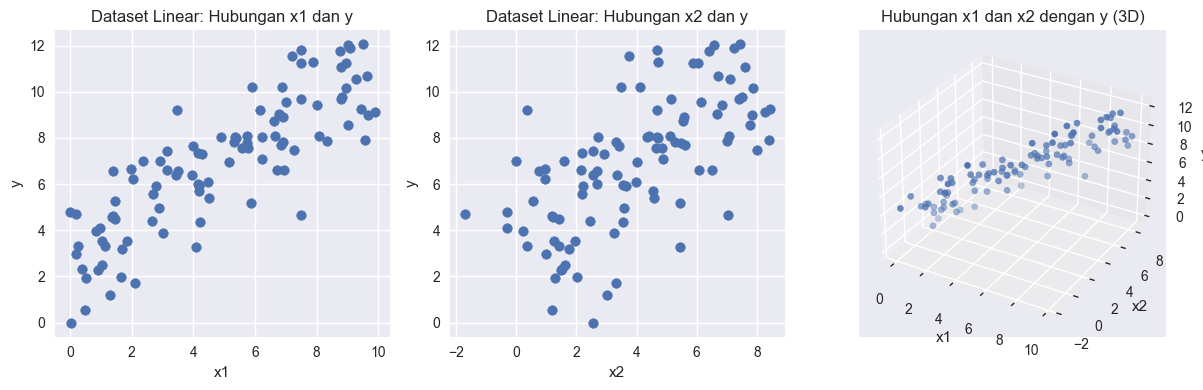

In [369]:
fig = plt.figure(figsize=(12,4))

# subplot 1 (kiri) -> 2D
ax1 = fig.add_subplot(1,3,1)
ax1.scatter(x1, y_linear)
ax1.set_xlabel("x1")
ax1.set_ylabel("y")
ax1.set_title("Dataset Linear: Hubungan x1 dan y")

# subplot 2 (tengah) -> 2D
ax1 = fig.add_subplot(1,3,2)
ax1.scatter(x2, y_linear)
ax1.set_xlabel("x2")
ax1.set_ylabel("y")
ax1.set_title("Dataset Linear: Hubungan x2 dan y")

# subplot 2 (kanan) -> 3D
ax2 = fig.add_subplot(1,3,3, projection='3d')
ax2.scatter(x1, x2, y_linear)

ax2.set_xlabel("x1")
ax2.set_ylabel("x2")
ax2.set_zlabel("y")
ax2.set_title("Hubungan x1 dan x2 dengan y (3D)")

plt.tight_layout()
plt.show()


In [370]:
# ============================================
# DATASET SINTETIS B - NONLINEAR EKSPONENSIAL
# ============================================

x_exp = np.linspace(0, 3, 100)

epsilon = np.random.normal(0, 2, 100)

y_exp = 2.5 * np.exp(0.8*x_exp) + epsilon


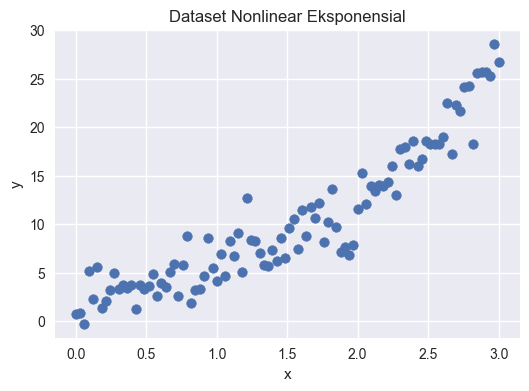

In [371]:
plt.figure(figsize=(6,4))

plt.scatter(x_exp, y_exp)

plt.xlabel("x")
plt.ylabel("y")

plt.title("Dataset Nonlinear Eksponensial")

plt.show()

In [372]:
# ============================================
# DATASET SINTETIS C - POWER LAW
# ============================================

x1_power = np.random.uniform(1, 10, n)
x2_power = np.random.uniform(1, 10, n)

epsilon = np.random.normal(0, 1, n)

y_power = 1.2*(x1_power**0.8)*(x2_power**0.5) + epsilon

data_power = pd.DataFrame({
    "x1": x1_power,
    "x2": x2_power,
    "y": y_power
})

data_power.head()


,x1,x2,y
0,6.026649,7.725887,15.001660
1,7.212051,3.606425,11.783535
2,5.075681,7.964194,13.726951
3,6.654781,4.849636,11.433079
4,3.610872,8.269286,10.274982


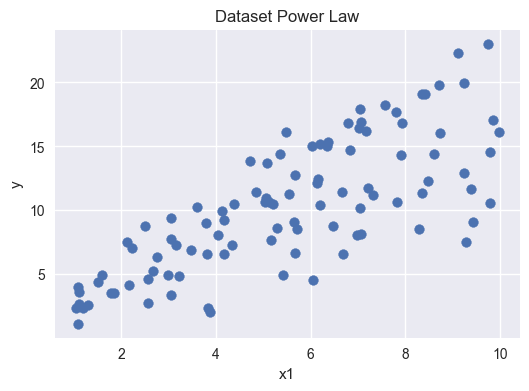

In [373]:
plt.figure(figsize=(6,4))

plt.scatter(x1_power, y_power)

plt.xlabel("x1")
plt.ylabel("y")

plt.title("Dataset Power Law")

plt.show()


## 7.3. Regresi Linear Tunggal (SLR) 

In [374]:
def slr(x, y):

    n = len(x)

    # Menjumlahan x
    sum_x = 0 
    sum_y = 0 
    sum_xy = 0
    sum_x2 = 0
    for i in range(n):
        sum_x += x[i]
        sum_y += y[i]
        sum_xy += x[i]*y[i]
        sum_x2 += x[i]*x[i]

    y_mean = sum_y/n
    x_mean = sum_x/n

    a1 = (n*sum_xy - sum_x*sum_y) / (n*sum_x2 - sum_x**2)

    a0 = y_mean - a1*x_mean

    return a0, a1


In [375]:
# ============================================
# SLR - Mengambil variabel dari dataset
# ============================================

x = data_linear["x1"].values
y = data_linear["y"].values


a, b = slr(x, y)

print("Intercept (a):", a)
print("Slope (b):", b)

Intercept (a): 2.886036099554597
Slope (b): 0.8209051129235383


In [376]:
y_pred = a + b*x

In [377]:
r2, rmse, mae = hitung_metrics(y, y_pred)

print("R2 :", r2)
print("RMSE :", rmse)
print("MAE :", mae)

R2 : 0.715817165711615
RMSE : 1.5227581464841182
MAE : 1.2176434191754133


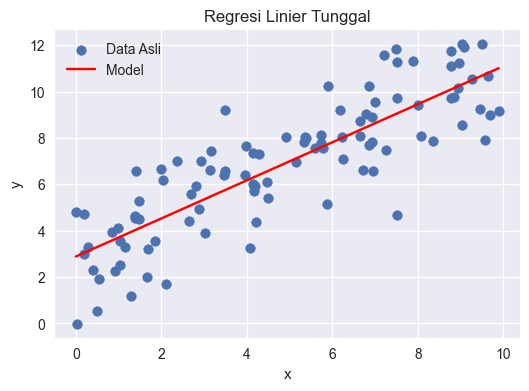

In [378]:
# urutkan x supaya garis tidak zigzag
idx = np.argsort(x)

plot_slr(x[idx], y[idx], y_pred[idx],)

## 7.4. Regresi Linear Ganda (MLR) + VIF 

In [379]:

# ============================================
# FUNGSI MLR (NORMAL EQUATION)
# ============================================

def mlr_normal_equation(X, y):
    
    # menghitung beta
    XtX = X.T @ X
    XtX_inv = np.linalg.inv(XtX)
    XtY = X.T @ y
    
    beta = XtX_inv @ XtY
    
    return beta


In [380]:
# ============================================
# MLR - MENYIAPKAN DATA
# ============================================

x1 = data_linear["x1"].values
x2 = data_linear["x2"].values
y = data_linear["y"].values

n = len(y)

# matriks X dengan kolom 1 untuk intercept
X = np.column_stack((np.ones(n), x1, x2))

# ============================================
# NORMAL EQUATION
# ============================================

XtX = X.T @ X
XtX_inv = np.linalg.inv(XtX)

XtY = X.T @ y

beta = XtX_inv @ XtY

a = beta[0]
b1 = beta[1]
b2 = beta[2]

print("Intercept (a) :", a)
print("Koef x1 (b1) :", b1)
print("Koef x2 (b2) :", b2)

Intercept (a) : 3.189284397624839
Koef x1 (b1) : 1.8043907048710148
Koef x2 (b2) : -1.2797595041327074


In [381]:

y_pred = X @ beta

In [382]:
r2, rmse, mae = hitung_metrics(y, y_pred)

print("R2 :", r2)
print("RMSE :", rmse)
print("MAE :", mae)


R2 : 0.8763461276855401
RMSE : 1.0044674582833175
MAE : 0.8076609329264821


In [383]:
# ============================================
# FUNGSI VIF
# ============================================

def hitung_vif(X):

    vif_values = []

    for i in range(X.shape[1]):

        Xi = X[:, i]

        X_others = np.delete(X, i, axis=1)

        beta = np.linalg.inv(X_others.T @ X_others) @ (X_others.T @ Xi)

        Xi_pred = X_others @ beta

        r2, _, _ = hitung_metrics(Xi, Xi_pred)

        vif = 1 / (1 - r2)

        vif_values.append(vif)

    return vif_values

In [384]:
X_vif = np.column_stack((x1, x2))

vif = hitung_vif(X_vif)

print("VIF x1 :", vif[0])
print("VIF x2 :", vif[1])

VIF x1 : 7.1471091943075615
VIF x2 : 7.263337451066227


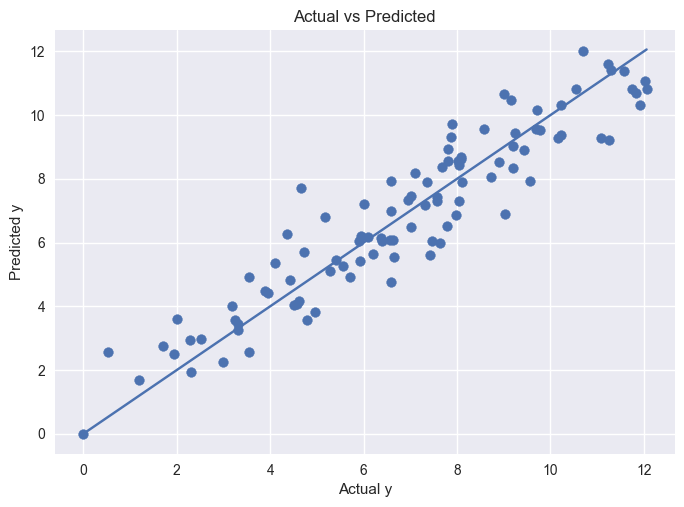

In [385]:
import matplotlib.pyplot as plt

plt.scatter(y, y_pred)
plt.plot([y.min(), y.max()], [y.min(), y.max()])

plt.xlabel("Actual y")
plt.ylabel("Predicted y")
plt.title("Actual vs Predicted")

plt.show()

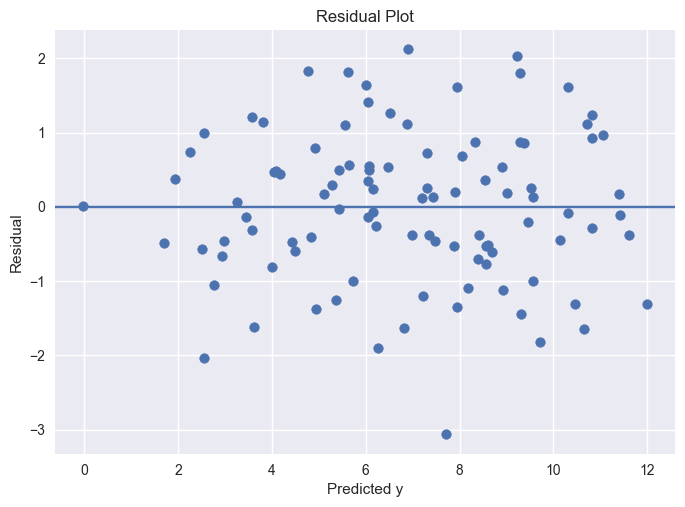

In [386]:
residual = y - y_pred

plt.scatter(y_pred, residual)
plt.axhline(0)

plt.xlabel("Predicted y")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()


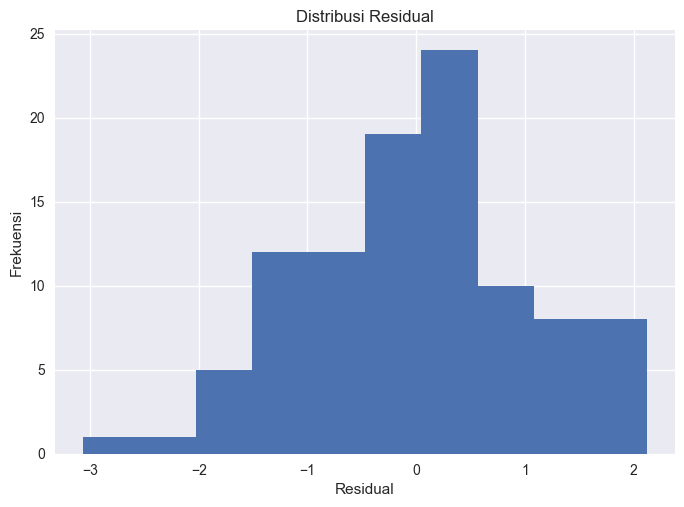

In [387]:
plt.hist(residual, bins=10)

plt.xlabel("Residual")
plt.ylabel("Frekuensi")
plt.title("Distribusi Residual")

plt.show()


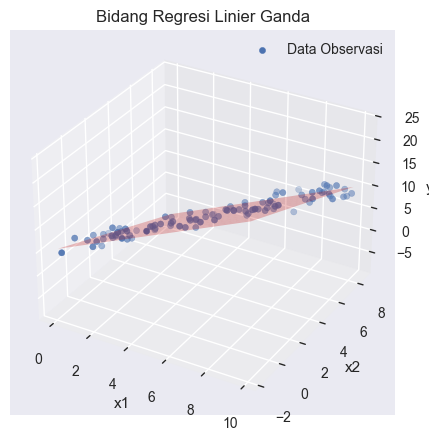

In [388]:
plot_mlr_plane(x1, x2, y, beta)